## Architettura

L’encoder riduce la risoluzione e produce un vettore latente da 64 dimensioni; il decoder ricostruisce un’immagine in `[0, 1]`.


## Training e valutazione

Il checkpoint usa la validation MSE; il test confronta modello e baseline rumorosa con MSE, PSNR e SSIM.


# 2. AutoEncoder per il denoising

Qui costruiamo il dataset noisy/clean, definiamo un AutoEncoder convoluzionale e osserviamo il miglioramento rispetto alla baseline dell’immagine rumorosa.


## Architettura

L’encoder riduce la risoluzione da `64x64` a `16x16` e comprime poi la rappresentazione in un vettore latente da 64 dimensioni. Il decoder esegue il percorso inverso e usa `Sigmoid` per produrre valori in `[0, 1]`.


## Training e valutazione

Il checkpoint viene scelto sulla validation reconstruction MSE. Sul test calcoliamo MSE globale, PSNR e SSIM, confrontando sempre anche l’input rumoroso senza modello.


# 2. Dataset noisy/clean, AutoEncoder e training


In [1]:
from pathlib import Path
import sys, torch, matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import EuroSAT
ROOT=Path.cwd()
while not (ROOT/'README.md').exists() and ROOT!=ROOT.parent: ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from eurosat_denoising.utils import *
seed_everything(42); DATA=ROOT/'data'; OUT=ROOT/'outputs'; OUT.mkdir(exist_ok=True); DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(ROOT,DEVICE)
dataset=EuroSAT(DATA,download=False); n=len(dataset); sizes=[int(.70*n),int(.15*n),n-int(.85*n)]
a,b,c=random_split(dataset,sizes,generator=torch.Generator().manual_seed(42)); corrupt=lambda x:add_gaussian_noise(x,.15)
train=NoisyCleanDataset(dataset,a.indices,corrupt); val=NoisyCleanDataset(dataset,b.indices,corrupt,1000); test=NoisyCleanDataset(dataset,c.indices,corrupt,2000)
tr=DataLoader(train,128,shuffle=True); va=DataLoader(val,128); te=DataLoader(test,128)


/home/alessandro/Desktop/eurosat-denoising cpu


In [2]:
from torch import nn
class AutoEncoder(nn.Module):
 def __init__(self,channels=32,latent=64):
  super().__init__(); self.enc=nn.Sequential(nn.Conv2d(3,channels,3,2,1),nn.ReLU(),nn.Conv2d(channels,latent,3,2,1),nn.ReLU()); self.dec=nn.Sequential(nn.ConvTranspose2d(latent,channels,4,2,1),nn.ReLU(),nn.ConvTranspose2d(channels,3,4,2,1),nn.Sigmoid())
 def forward(self,x): return self.dec(self.enc(x))
def epoch(model,loader,opt=None):
 model.train(opt is not None); total=0
 for noisy,clean in loader:
  noisy,clean=noisy.to(DEVICE),clean.to(DEVICE); pred=model(noisy); loss=nn.functional.mse_loss(pred,clean)
  if opt: opt.zero_grad();loss.backward();opt.step()
  total+=loss.item()*len(noisy)
 return total/len(loader.dataset)
model=AutoEncoder().to(DEVICE); opt=torch.optim.Adam(model.parameters(),1e-3); hist={'train':[],'val':[]}; best=1e9
for e in range(1,6):
 tl=epoch(model,tr,opt); vl=epoch(model,va); hist['train'].append(tl);hist['val'].append(vl)
 if vl<best: best=vl;torch.save(model.state_dict(),OUT/'autoencoder_best.pt')
 print(e,tl,vl)
model.load_state_dict(torch.load(OUT/'autoencoder_best.pt',map_location=DEVICE))


1 0.008292103200687696 0.002913261914142856
2 0.002346250051361504 0.0019821529698063746
3 0.0018901796372873443 0.001764523657096297
4 0.001710023951085984 0.001604109194279177
5 0.001575763675941046 0.0015317083239831306


<All keys matched successfully>

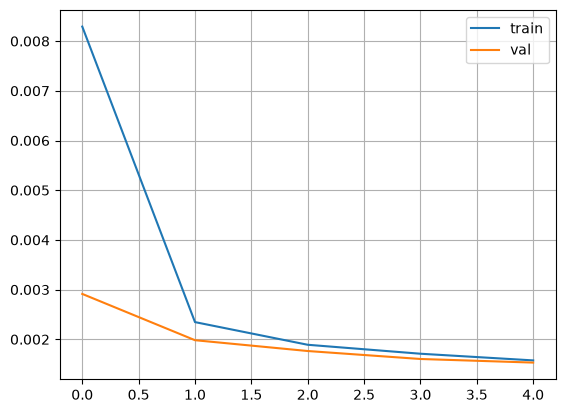

baseline 0.021185403050463878 16.73966139525634 AE 0.0015276076516458465 28.17059028169474


In [3]:
plt.plot(hist['train'],label='train');plt.plot(hist['val'],label='val');plt.legend();plt.grid();plt.show()
model.eval(); bm=bp=mm=mp=0; count=0
with torch.no_grad():
 for noisy,clean in te:
  pred=model(noisy.to(DEVICE)).cpu(); k=len(noisy);count+=k;bm+=mse_score(noisy,clean)*k;bp+=psnr_score(noisy,clean)*k;mm+=mse_score(pred,clean)*k;mp+=psnr_score(pred,clean)*k
print('baseline',bm/count,bp/count,'AE',mm/count,mp/count)
